# 01 · Data provenance, eligibility and cleaning

**Research population:** responding Mexican small-cargo operators (not a probability sample of all Mexican operators).

**Purpose:** document the exact source file, screening, duplicate treatment, conservative category normalization, and target coding. Original questionnaire answers remain intact.

The downstream analysis has **two distinct binary targets**, current EV use and EV consideration. Here we inspect both to establish valid denominators, not to train models.

## Environment and original source

In [1]:
from pathlib import Path
import sys
ROOT = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p/'src'/'ev_research').exists())
if str(ROOT) not in sys.path:
    sys.path.insert(0, str(ROOT))
import numpy as np
import pandas as pd
from IPython.display import display, Image
from src.ev_research.data import load_survey, sample_audit, cleaning_audit
from src.ev_research.config import FIGURES, TABLES, FEATURE_SETS, SOURCE_INDEX
from src.ev_research.plotting_style import apply_style
from src.ev_research.statistics import prevalence_table, assumptions_audit, fisher_associations, sensitivity_table
from src.ev_research.figures import *
apply_style()
raw, unique, eligible = load_survey()
print(f'Raw: {len(raw)} | Distinct: {len(unique)} | Eligible: {len(eligible)}')
def show_figure(path, width=1150):
    """Display the exact saved PNG (also exported as vector SVG)."""
    assert path.exists(), f'Missing figure: {path}'
    display(Image(filename=str(path), width=width))


Raw: 105 | Distinct: 92 | Eligible: 62


## 1. Survey eligibility and denominators

We remove exact-row duplicates before screening for small-cargo operators. Missing outcome responses are excluded only for the relevant question. A company can have one outcome valid and the other missing.

,stage,n
0,Original records,105
1,Exact duplicates,13
2,Unique response rows,92
3,Eligible unique responses,62
4,Valid ev_use responses,60
5,Positive ev_use responses,15
6,Valid ev_consideration responses,59
7,Positive ev_consideration responses,34


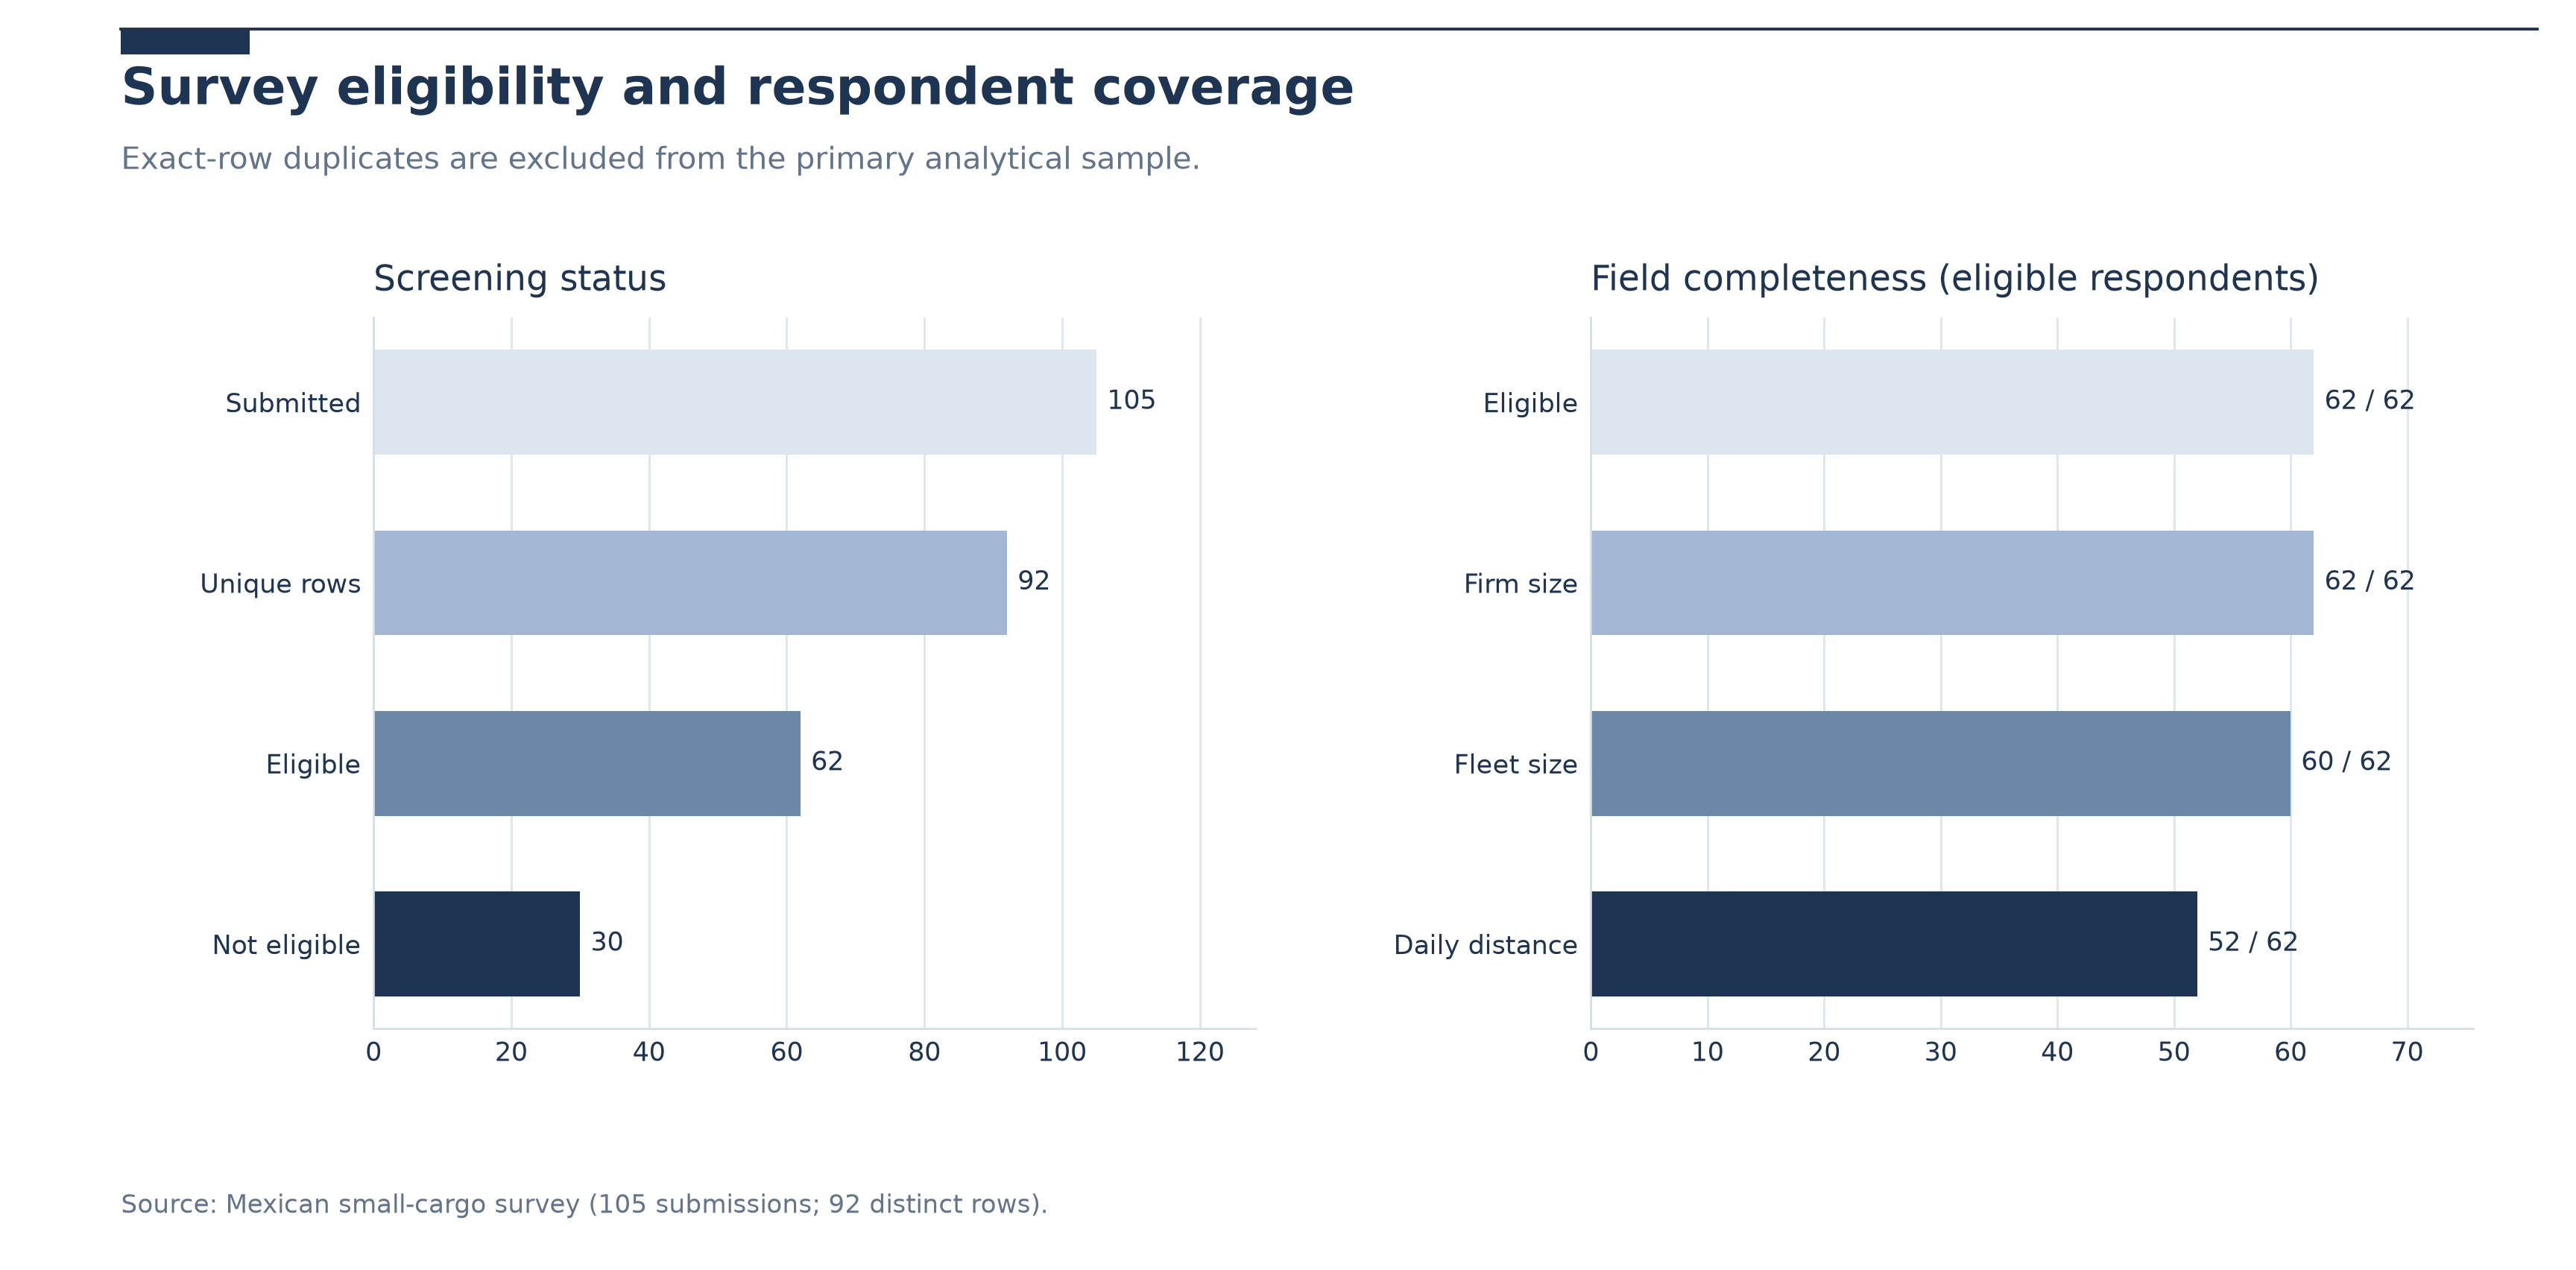

In [2]:
audit = sample_audit(raw, unique, eligible)
display(audit)
assert len(raw)==105 and len(unique)==92 and len(eligible)==62
assert eligible.firm_size.value_counts().to_dict() == {'Small':29,'Large':22,'Medium':11}
plot_eligibility_and_coverage(raw, unique, eligible)
show_figure(FIGURES/'01_data_quality'/'01_survey_eligibility_and_coverage.png')

## 2. Harmonization quality

The raw-to-canonical mapping includes explicit quality flags. For example, distance per trip must not be treated as kilometers per day; ranges crossing canonical boundaries remain ambiguous. Neither missingness nor ambiguously interpreted values are silently imputed in descriptive figures.

,variable,quality,n
0,acquisition_type_quality,mapped,51
1,acquisition_type_quality,missing,11
2,daily_distance_quality,crosses_120km_threshold,1
3,daily_distance_quality,incompatible_unit,3
4,daily_distance_quality,mapped,49
5,daily_distance_quality,missing,6
6,daily_distance_quality,range_inferred_km_per_day,1
7,daily_distance_quality,unit_inferred_from_question,2
8,firm_size_quality,mapped,62
9,fleet_size_quality,mapped,59



 firm_size


firm_size  firm_size_quality
Small      mapped               29
Large      mapped               22
Medium     mapped               11
Name: n, dtype: int64


 fleet_size


fleet_size  fleet_size_quality
1-10        mapped                31
11-50       mapped                15
>400        mapped                 6
200-400     mapped                 4
51-200      mapped                 3
>400        numeric_to_band        1
NaN         missing                1
            unclassified           1
Name: n, dtype: int64


 daily_distance


daily_distance  daily_distance_quality     
31-60 km/day    mapped                         22
61-120 km/day   mapped                         12
>120 km/day     mapped                         10
NaN             missing                         6
<20 km/day      mapped                          5
NaN             incompatible_unit               3
61-120 km/day   range_inferred_km_per_day       1
                unit_inferred_from_question     1
NaN             crosses_120km_threshold         1
>120 km/day     unit_inferred_from_question     1
Name: n, dtype: int64


 sector


sector                         sector_quality
Logistics and parcel delivery  mapped            39
Services                       mapped             8
Retail                         mapped             8
Food and distribution          mapped             6
NaN                            missing            1
Name: n, dtype: int64

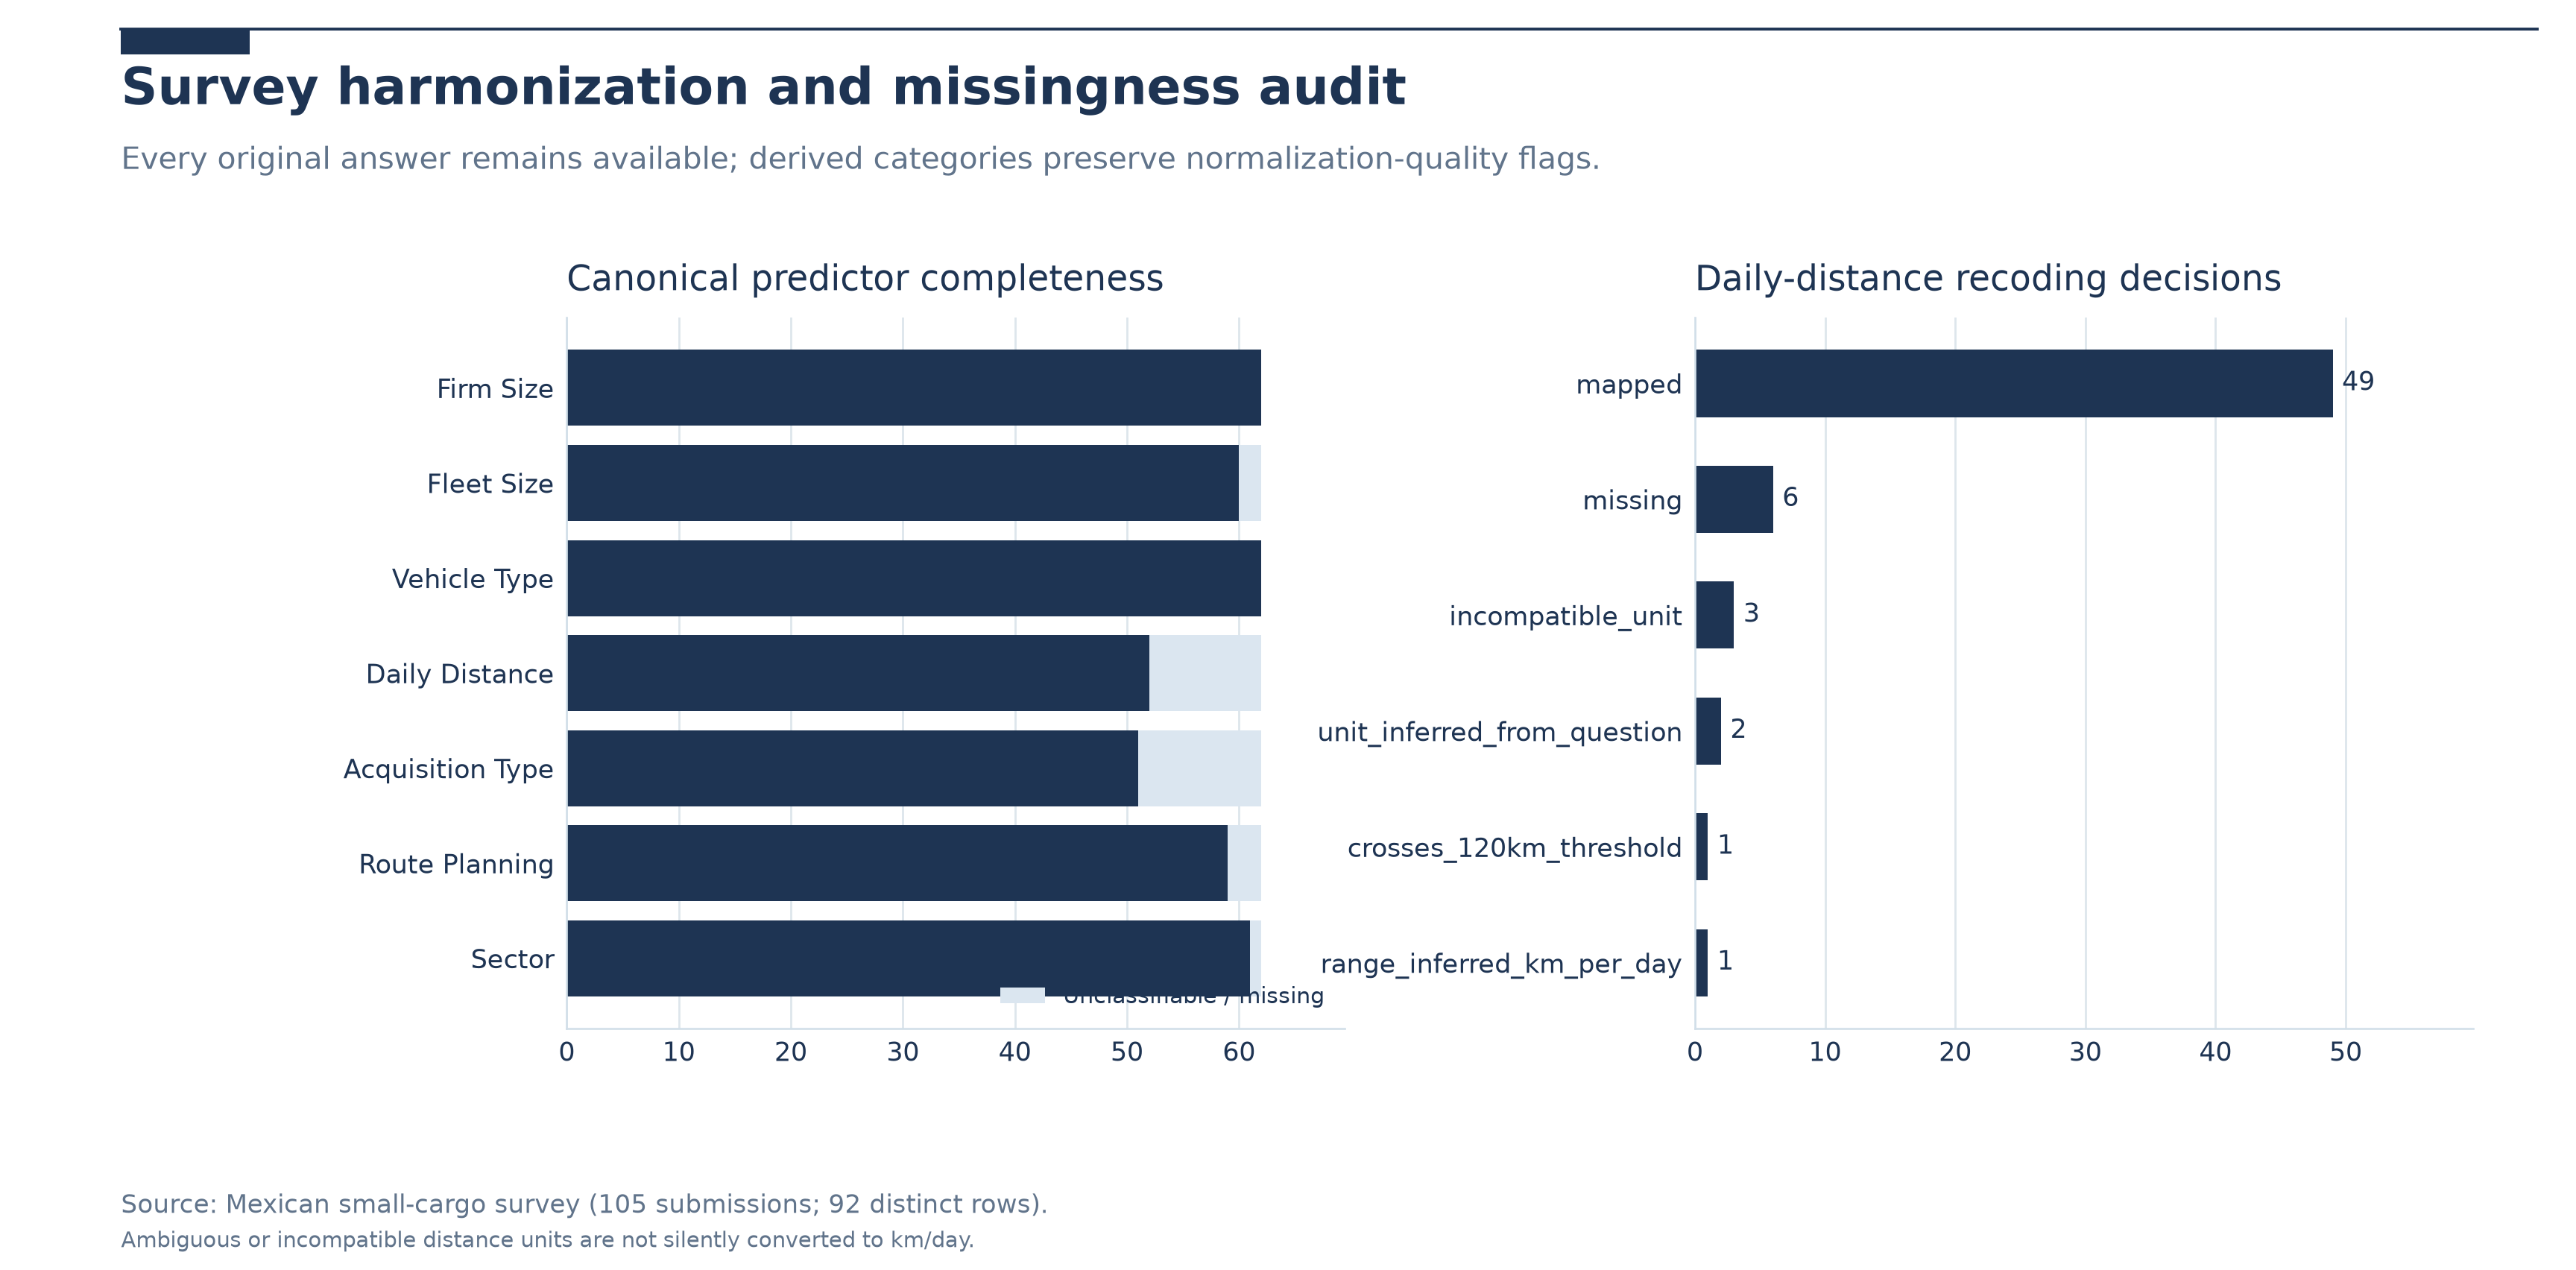

In [3]:
quality = cleaning_audit(eligible)
display(quality)
for name in ['firm_size','fleet_size','daily_distance','sector']:
    print('\n', name)
    display(eligible[[name, f'{name}_quality']].value_counts(dropna=False).rename('n').head(12))
plot_cleaning_quality(eligible)
show_figure(FIGURES/'01_data_quality'/'03_normalization_and_missingness.png')

## 3. Outcome encoding and observed prevalence

For respondent \(i\), define \(Y_i^{(use)}\in\{0,1\}\) and \(Y_i^{(consider)}\in\{0,1\}\). For each valid-response set \(S_j\):

\[\widehat p_j = \frac{\sum_{i\in S_j}Y_i^{(j)}}{|S_j|}.\]

Wilson intervals describe an idealized independent-response binomial model; they do **not** correct selection bias or confer national representativeness.

,outcome,positive,negative,n,rate,wilson_95_low,wilson_95_high
0,ev_use,15,45,60,0.250000,0.157765,0.372321
1,ev_consideration,34,25,59,0.576271,0.449345,0.693873


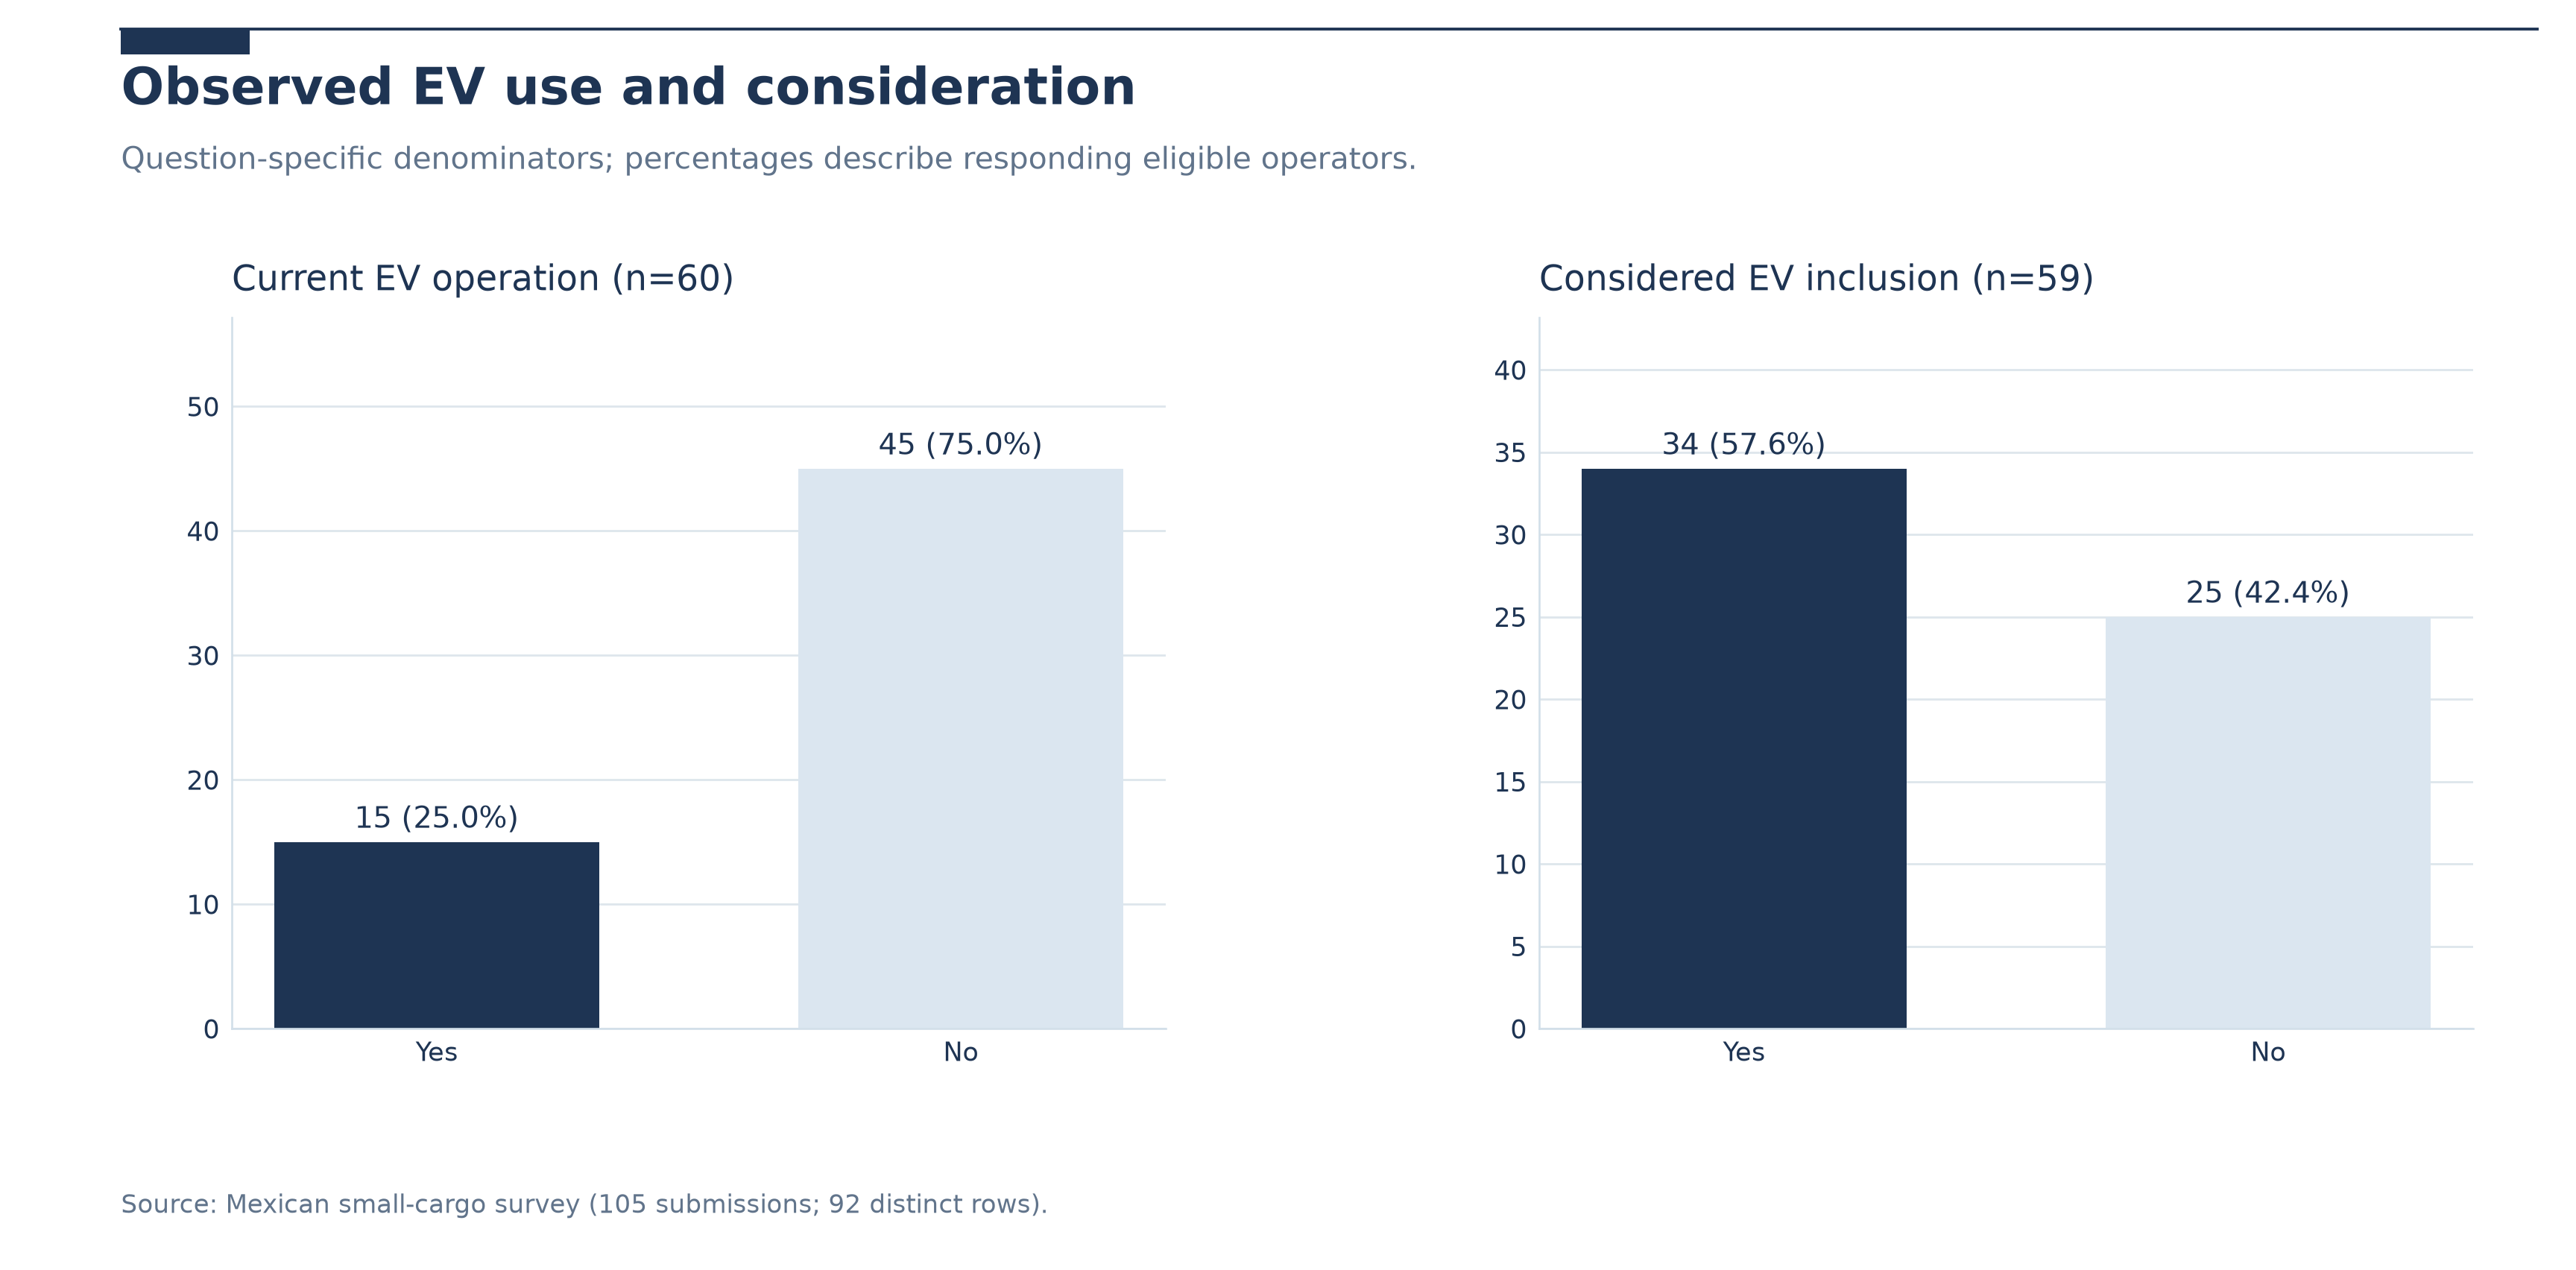

In [4]:
prevalence = prevalence_table(eligible)
display(prevalence)
plot_observed_ev_outcomes(eligible)
show_figure(FIGURES/'01_data_quality'/'02_observed_ev_use_and_consideration.png')

## 4. Store the canonical eligible dataset

The processed export is for reproducibility within a **private** research environment. It retains original answer columns and therefore should not be uploaded to a public GitHub repository.

In [5]:
from src.ev_research.config import PROCESSED
PROCESSED.mkdir(parents=True, exist_ok=True)
# Opt-in: uncomment to refresh the sensitive respondent-level CSV.
# eligible.to_csv(PROCESSED/'eligible_canonical.csv', index=False)
print('Canonical sample:',eligible.shape, '| Raw source retained without modification')

Canonical sample: (62, 50) | Raw source retained without modification


**Limitations.** Exact duplicates are not necessarily distinct individuals; exclusions must be documented. Self-reports are not operational EV telemetry. Questionnaire category normalization is an analytical choice, not a fact about kilometers or monetary cash flows.